1. Importing libraries 

In [1]:
from collections.abc import Callable

import matplotlib.pyplot as plt
import numpy as np
import tensorflow as tf
from matplotlib import colors

2. Define input and output features 

In [2]:
INPUT_FEATURES = [
    "elevation",
    "th",
    "vs",
    "tmmn",
    "tmmx",
    "sph",
    "pr",
    "pdsi",
    "NDVI",
    "population",
    "erc",
    "PrevFireMask",
]
OUTPUT_FEATURES = ["FireMask"]

train_file = "/kaggle/input/next-day-wildfire-spread/next_day_wildfire_spread_train*"
test_file = "/kaggle/input/next-day-wildfire-spread/next_day_wildfire_spread_test*"
validation_file = "/kaggle/input/next-day-wildfire-spread/next_day_wildfire_spread_eval*"

3. Parse TFRecord files

The provided dataset are Tensor Flow Record (TFR) files. We need to parse these to extract the features and labels

In [3]:
def normalize_feature(feature, feature_name):
    """
    Normalization of input features based on their type.

    Args:
        feature (Tensor): The feature tensor to be normalized.
        feature_name (str): Name of the feature, used to determine the type.

    Returns:
        Tensor: The normalized feature. For 'PrevFireMask', the feature is returned unchanged.
                Other features are normalized to the range [-1, 1].
    """
    if feature_name == "PrevFireMask":
        # Fire mask is already binary
        return feature
    else:
        # Normalize other features to [-1, 1] range
        return (feature - tf.reduce_mean(feature)) / (tf.math.reduce_std(feature) + 1e-6)


def _parse_function(example_proto):
    """
    Parsing and preprocessing of a serialized TFRecord example.

    Args:
        example_proto (Tensor): A serialized TFRecord example.

    Returns:
        Tuple[Tensor, Tensor]:
            - inputs: A tensor containing concatenated and normalized input features
                      with shape [64, 64, num_features].
            - label: A tensor containing the processed FireMask label with shape [64, 64, 1].
    """

    # Feature description dictionary: specifies the shape and types of features
    feature_description = {}
    for feature_name in INPUT_FEATURES + OUTPUT_FEATURES:
        feature_description[feature_name] = tf.io.FixedLenFeature([64, 64], tf.float32)

    # Parse the input tf.train.Example proto using the dictionary above
    parsed_example = tf.io.parse_single_example(example_proto, feature_description)

    # Create a single tensor from the input features
    inputs_list = []
    for feature_name in INPUT_FEATURES:
        feature = tf.expand_dims(
            parsed_example[feature_name], axis=-1
        )  # Expand dimensions to make sure each feature has shape [64, 64, 1]
        normalized_feature = normalize_feature(feature, feature_name)

        inputs_list.append(normalized_feature)
    inputs = tf.concat(inputs_list, axis=-1)  # Shape of inputs: [64, 64, 12]

    # The label (FireMask), is expanded to have a shape [64,64,1]

    label = tf.expand_dims(parsed_example["FireMask"], axis=-1)  # Shape of output: [64, 64, 1]

    label = tf.where(label < 0, 0.0, label)
    label = tf.where(label > 0, 1.0, label)
    return inputs, label

4. Create a getter to load in dataset for processing

In [4]:
def get_dataset(file_pattern: str, batch_size: int) -> tf.data.Dataset:
    """
    Creation and preprocessing of a dataset for training or evaluation.

    Args:
        file_pattern (Text): File path pattern to match TFRecord files.
        batch_size (int): Number of samples per batch.

    Returns:
        tf.data.Dataset: A preprocessed dataset with shuffled, batched, and prefetched data.
    """

    dataset = tf.data.Dataset.list_files(
        file_pattern
    )  # Creates a dataset of filepaths matching file_pattern, which each filepath representing a TFRecord file
    dataset = dataset.interleave(
        lambda x: tf.data.TFRecordDataset(
            x
        ),  # Opens file and creates a TFRecordDataset, which reads the serialized examples from the file.
        num_parallel_calls=tf.data.AUTOTUNE,  # enable automatic parallel processing
    )
    dataset = dataset.map(
        _parse_function, num_parallel_calls=tf.data.AUTOTUNE
    )  # parse the serialized data in each TFRecord to split inputs and labels (see previous cell)
    dataset = dataset.shuffle(
        buffer_size=1000
    )  # Randomly shuffles the data by using a buffer of size 1000 (random samples are taken from buffer)
    dataset = dataset.batch(
        batch_size
    )  # Batch = subset of data the we expose the model to during training
    dataset = dataset.prefetch(
        buffer_size=tf.data.experimental.AUTOTUNE
    )  # speeds up training by overlapping preprocessing and model execution
    return dataset

5. Load dataset 

In [5]:
BATCH_SIZE = 16
train_dataset = get_dataset(train_file, batch_size=BATCH_SIZE)
validation_dataset = get_dataset(validation_file, batch_size=BATCH_SIZE)
test_dataset = get_dataset(test_file, batch_size=BATCH_SIZE)

6. Define the Convolutional Neural Network



In [6]:
from tensorflow.keras import layers, models


def conv_block(x, filters, kernel_size=3):
    x = layers.Conv2D(filters, kernel_size, padding="same")(x)
    x = layers.BatchNormalization()(x)
    x = layers.ReLU()(x)
    x = layers.Conv2D(filters, kernel_size, padding="same")(x)
    x = layers.BatchNormalization()(x)
    return layers.ReLU()(x)


def attention_gate(x, g, inter_channels):
    theta_x = layers.Conv2D(inter_channels, 1, padding="same")(x)
    phi_g = layers.Conv2D(inter_channels, 1, padding="same")(g)
    concat = layers.Activation("relu")(theta_x + phi_g)
    psi = layers.Conv2D(1, 1, padding="same", activation="sigmoid")(concat)
    return layers.Multiply()([x, psi])


def build_attention_unet(input_shape=(64, 64, 12)):
    inputs = layers.Input(input_shape)

    # Encoder
    c1 = conv_block(inputs, 64)
    p1 = layers.MaxPooling2D()(c1)

    c2 = conv_block(p1, 128)
    p2 = layers.MaxPooling2D()(c2)

    c3 = conv_block(p2, 256)
    p3 = layers.MaxPooling2D()(c3)

    c4 = conv_block(p3, 512)
    p4 = layers.MaxPooling2D()(c4)

    # Bridge
    bn = conv_block(p4, 1024)

    # Decoder
    up4 = layers.UpSampling2D()(bn)
    att4 = attention_gate(c4, up4, 512)
    m4 = layers.Concatenate()([up4, att4])
    dc4 = conv_block(m4, 512)

    up3 = layers.UpSampling2D()(dc4)
    att3 = attention_gate(c3, up3, 256)
    m3 = layers.Concatenate()([up3, att3])
    dc3 = conv_block(m3, 256)

    up2 = layers.UpSampling2D()(dc3)
    att2 = attention_gate(c2, up2, 128)
    m2 = layers.Concatenate()([up2, att2])
    dc2 = conv_block(m2, 128)

    up1 = layers.UpSampling2D()(dc2)
    att1 = attention_gate(c1, up1, 64)
    m1 = layers.Concatenate()([up1, att1])
    dc1 = conv_block(m1, 64)

    # Output
    outputs = layers.Conv2D(1, 1, activation="sigmoid")(dc1)

    return models.Model(inputs, outputs)

In [13]:
def focal_loss_tf(y_true, y_pred, alpha=0.25, gamma=2.0):
    y_true = tf.cast(y_true, tf.float32)
    epsilon = tf.keras.backend.epsilon()
    y_pred = tf.clip_by_value(y_pred, epsilon, 1.0 - epsilon)
    cross_entropy = -y_true * tf.math.log(y_pred) - (1 - y_true) * tf.math.log(1 - y_pred)
    weight = alpha * tf.pow(1 - y_pred, gamma) * y_true + (1 - alpha) * tf.pow(y_pred, gamma) * (
        1 - y_true
    )
    return tf.reduce_mean(weight * cross_entropy)


def combined_focal_dice_loss(y_true, y_pred):
    return focal_loss_tf(y_true, y_pred) + dice_loss(y_true, y_pred)


def iou_metric(y_true, y_pred):
    y_pred = tf.cast(y_pred > 0.5, tf.float32)
    intersection = tf.reduce_sum(y_true * y_pred)
    union = tf.reduce_sum(tf.cast(tf.math.logical_or(y_true > 0.5, y_pred > 0.5), tf.float32))
    return tf.math.divide_no_nan(intersection, union)

In [14]:
model = build_attention_unet()

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss=combined_focal_dice_loss,  # your combo loss
    metrics=["accuracy", iou_metric],
)

model.summary()

Model: "functional_7"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_3       │ (None, 64, 64,    │          0 │ -                 │
│ (InputLayer)        │ 12)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_93 (Conv2D)  │ (None, 64, 64,    │      6,976 │ input_layer_3[0]… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_93[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_54 (ReLU)     │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_94 (Conv2D)  │ (None, 64, 64,    │     36,928 │ re_lu_54[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 64, 64,    │        256 │ conv2d_94[0][0]   │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_55 (ReLU)     │ (None, 64, 64,    │          0 │ batch_normalizat… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_12    │ (None, 32, 32,    │          0 │ re_lu_55[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_95 (Conv2D)  │ (None, 32, 32,    │     73,856 │ max_pooling2d_12… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        512 │ conv2d_95[0][0]   │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_56 (ReLU)     │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_96 (Conv2D)  │ (None, 32, 32,    │    147,584 │ re_lu_56[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 32, 32,    │        512 │ conv2d_96[0][0]   │
│ (BatchNormalizatio… │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_57 (ReLU)     │ (None, 32, 32,    │          0 │ batch_normalizat… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_13    │ (None, 16, 16,    │          0 │ re_lu_57[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_97 (Conv2D)  │ (None, 16, 16,    │    295,168 │ max_pooling2d_13… │
│                     │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_normalizatio… │ (None, 16, 16,    │      1,024 │ conv2d_97[0][0] 

 Total params: 32,455,045 (123.81 MB)

 Trainable params: 32,443,269 (123.76 MB)

 Non-trainable params: 11,776 (46.00 KB)

In [15]:
EPOCHS = 10
BATCH_SIZE = 32  # already used while building train_dataset

tf.random.set_seed(1337)

model.fit(
    train_dataset,  # already batched!
    epochs=EPOCHS,
    validation_data=validation_dataset,
)

Epoch 1/10


I0000 00:00:1742814692.968861      90 service.cc:145] XLA service 0x7ce69000c040 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1742814692.968928      90 service.cc:153]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1742814692.968935      90 service.cc:153]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5


      1/Unknown 35s 35s/step - accuracy: 0.7703 - iou_metric: 0.0055 - loss: 1.0867

I0000 00:00:1742814712.548547      90 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


    937/Unknown 143s 115ms/step - accuracy: 0.9685 - iou_metric: 0.1765 - loss: 0.8948

/opt/conda/lib/python3.10/contextlib.py:153: UserWarning: Your input ran out of data; interrupting training. Make sure that your dataset or generator can generate at least `steps_per_epoch * epochs` batches. You may need to use the `.repeat()` function when building your dataset.
  self.gen.throw(typ, value, traceback)


937/937 ━━━━━━━━━━━━━━━━━━━━ 152s 126ms/step - accuracy: 0.9685 - iou_metric: 0.1765 - loss: 0.8947 - val_accuracy: 0.9785 - val_iou_metric: 0.1982 - val_loss: 0.7608
Epoch 2/10
937/937 ━━━━━━━━━━━━━━━━━━━━ 99s 106ms/step - accuracy: 0.9853 - iou_metric: 0.2564 - loss: 0.6663 - val_accuracy: 0.9808 - val_iou_metric: 0.1990 - val_loss: 0.7172
Epoch 3/10
937/937 ━━━━━━━━━━━━━━━━━━━━ 99s 105ms/step - accuracy: 0.9867 - iou_metric: 0.2839 - loss: 0.6037 - val_accuracy: 0.9818 - val_iou_metric: 0.2054 - val_loss: 0.7040
Epoch 4/10
937/937 ━━━━━━━━━━━━━━━━━━━━ 99s 105ms/step - accuracy: 0.9882 - iou_metric: 0.3083 - loss: 0.5679 - val_accuracy: 0.9852 - val_iou_metric: 0.1797 - val_loss: 0.7325
Epoch 5/10
937/937 ━━━━━━━━━━━━━━━━━━━━ 99s 105ms/step - accuracy: 0.9891 - iou_metric: 0.3168 - loss: 0.5544 - val_accuracy: 0.9829 - val_iou_metric: 0.2048 - val_loss: 0.7031
Epoch 6/10
937/937 ━━━━━━━━━━━━━━━━━━━━ 99s 105ms/step - accuracy: 0.9893 - iou_metric: 0.3437 - loss: 0.5239 - val_accuracy:

In [20]:
import tensorflow as tf


def IoU_metric(real_mask: tf.Tensor, predicted_mask: tf.Tensor) -> float:
    real_mask = tf.where(real_mask < 0, 0, real_mask).numpy().astype(np.uint8)
    predicted_mask = predicted_mask.numpy().astype(np.uint8)

    intersection = np.logical_and(real_mask, predicted_mask)
    union = np.logical_or(real_mask, predicted_mask)

    if np.sum(union) == 0:
        return 1.0  # Perfect if both are empty
    return np.sum(intersection) / np.sum(union)


def evaluate_model(model, eval_dataset: tf.data.Dataset) -> float:
    IoU_measures = []

    for inputs, labels in eval_dataset:
        predictions = model.predict(inputs)
        predictions = tf.where(predictions > 0.5, 1, 0)

        for i in range(inputs.shape[0]):
            iou = IoU_metric(labels[i, :, :, 0], predictions[i, :, :, 0])
            IoU_measures.append(iou)

    return np.mean(IoU_measures)

In [21]:
# Test loss and IoU metric
print("Evaluate on test data")

IoU = evaluate_model(model, test_dataset)

print(f"IoU Score: {IoU:.4f}")

Evaluate on test data
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 

In [22]:
def show_inference(
    n_rows: int,
    features: tf.Tensor,
    label: tf.Tensor,
    prediction_function: Callable[[tf.Tensor], tf.Tensor],
) -> None:
    """
    Show model inference through images.

    Args:
        n_rows (int): Number of rows for subplots.
        features (tf.Tensor): Input features.
        label (tf.Tensor): True labels.
        prediction_function (Callable[[tf.Tensor], tf.Tensor]): Function for model prediction.
    """

    # Variables for controllong the color map for the fire masks
    CMAP = colors.ListedColormap(["black", "silver", "orangered"])
    BOUNDS = [-1, -0.1, 0.001, 1]
    NORM = colors.BoundaryNorm(BOUNDS, CMAP.N)

    fig = plt.figure(figsize=(15, n_rows * 4))

    prediction = prediction_function(features)
    for i in range(n_rows):
        plt.subplot(n_rows, 3, i * 3 + 1)
        plt.title("Previous day fire")
        plt.imshow(features[i, :, :, -1], cmap=CMAP, norm=NORM)
        plt.axis("off")
        plt.subplot(n_rows, 3, i * 3 + 2)
        plt.title("True next day fire")
        plt.imshow(label[i, :, :, 0], cmap=CMAP, norm=NORM)
        plt.axis("off")
        plt.subplot(n_rows, 3, i * 3 + 3)
        plt.title("Predicted next day fire")
        plt.imshow(prediction[i, :, :])
        plt.axis("off")
    plt.tight_layout()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step


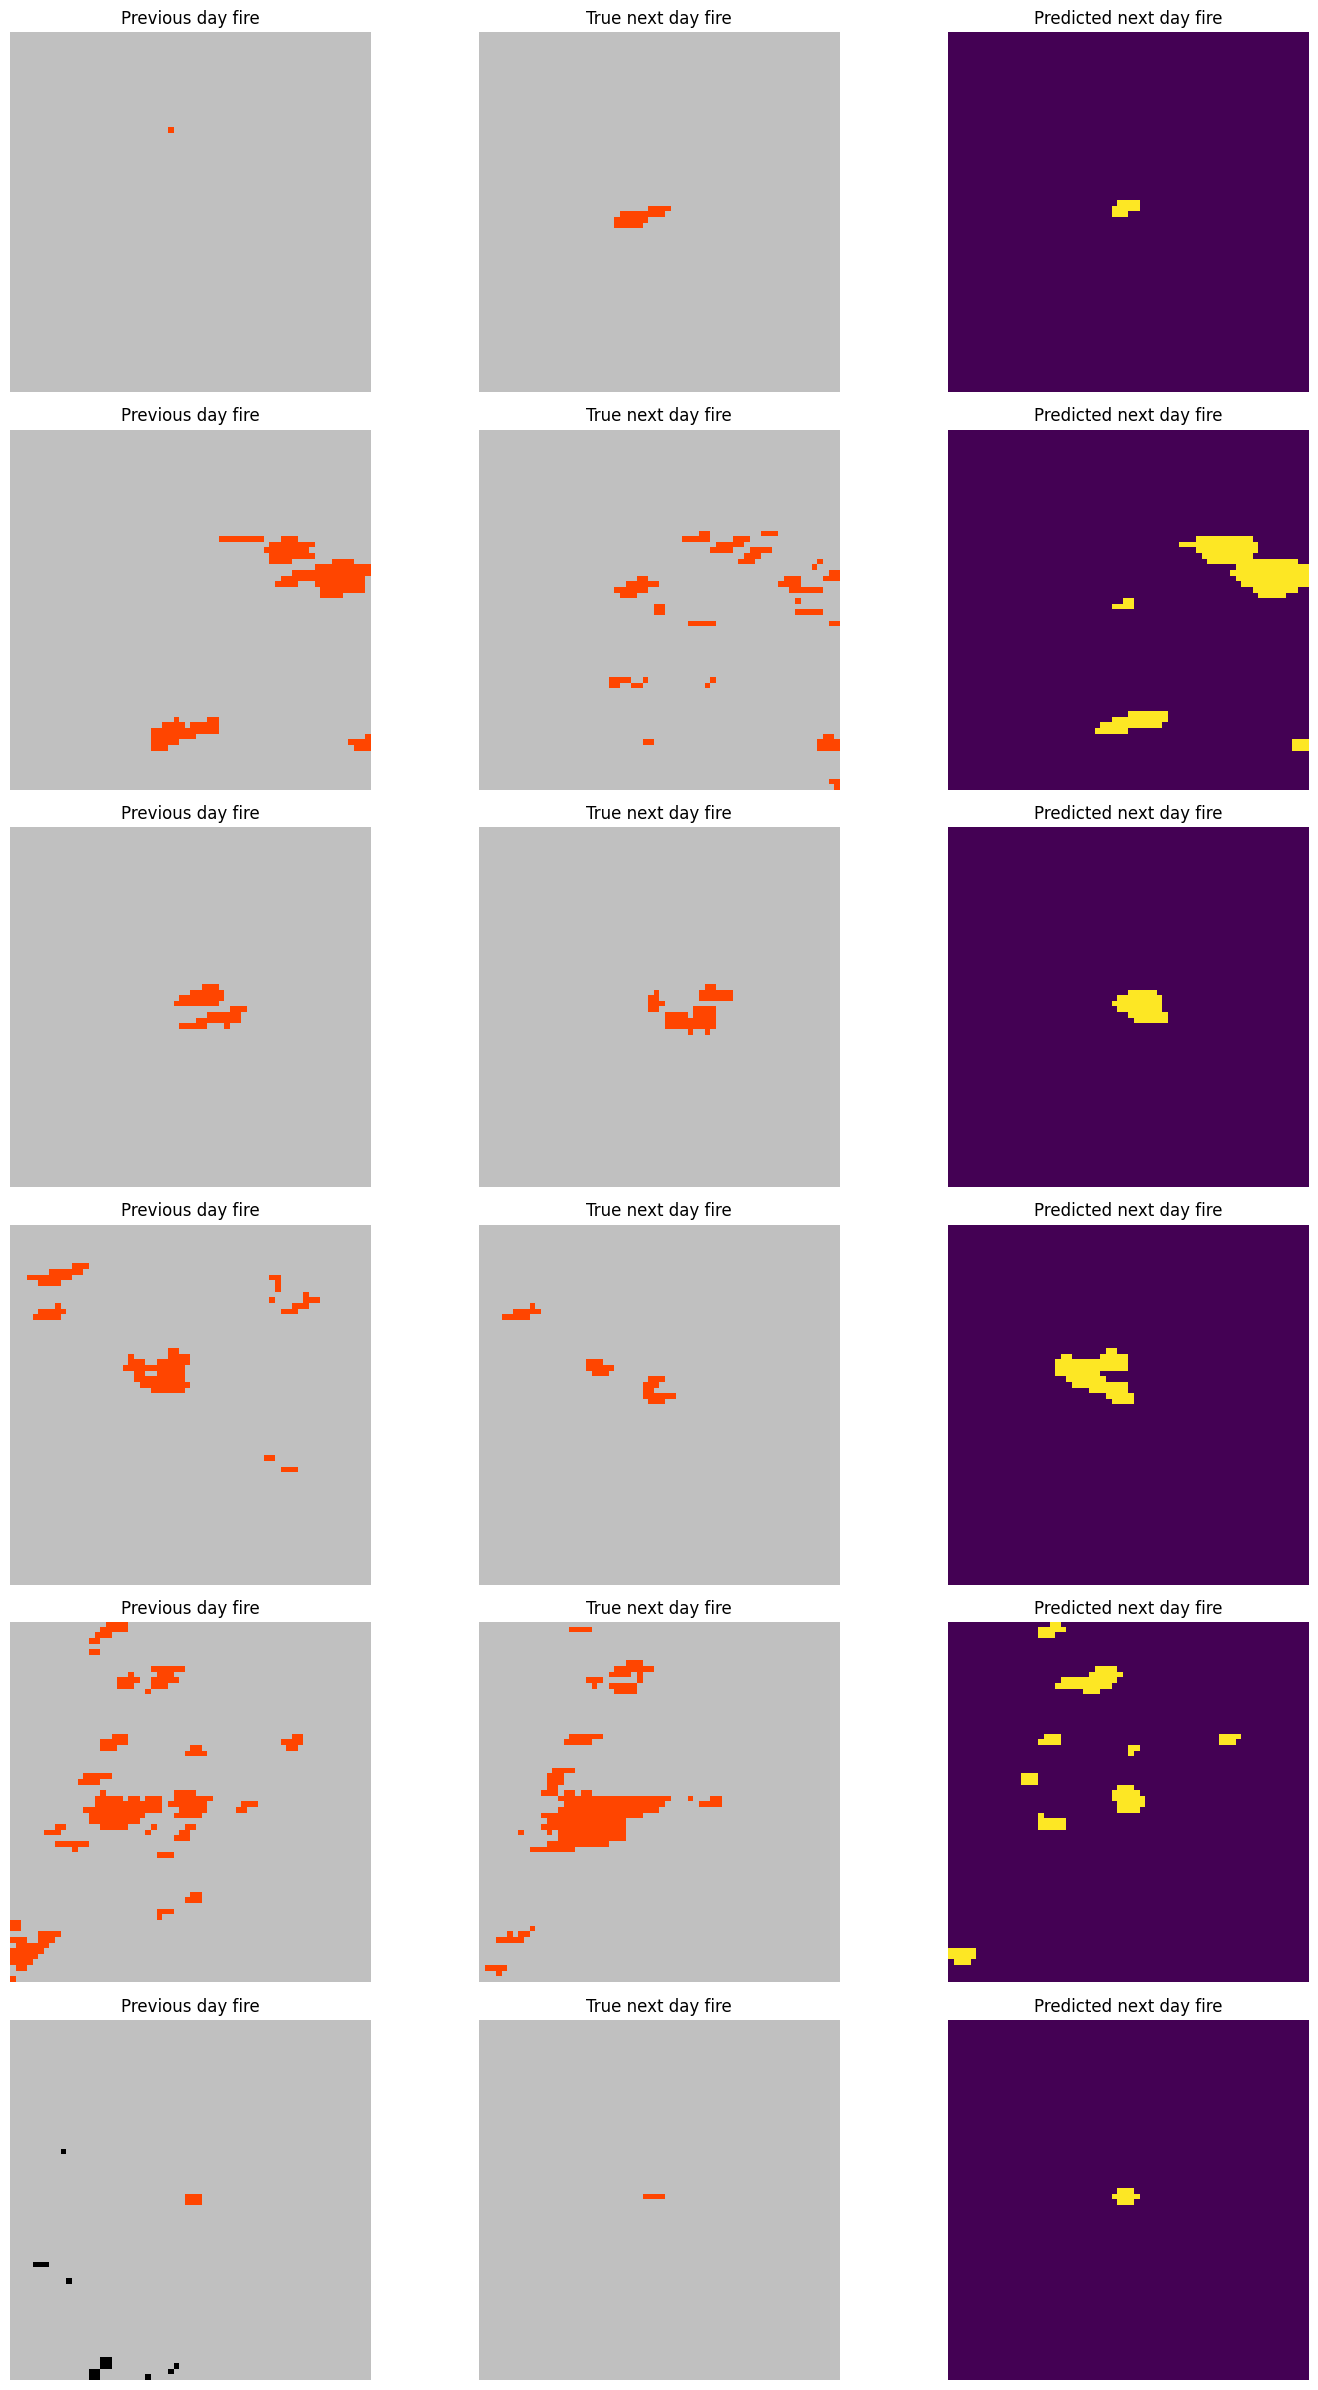

In [23]:
features, labels = next(iter(test_dataset))
show_inference(6, features, labels, lambda x: tf.where(model.predict(x) > 0.5, 1, 0)[:, :, :, 0])

# Data visualization

Define the names for each of our variables

In [8]:
TITLES = [
    "Elevation",
    "Wind\ndirection",
    "Wind\nvelocity",
    "Min\ntemp",
    "Max\ntemp",
    "Humidity",
    "Precip",
    "Drought",
    "Vegetation",
    "Population\ndensity",
    "Energy\nrelease\ncomponent",
    "Previous\nfire\nmask",
    "Fire\nmask",
]

In [9]:
def plot_samples_from_dataset(dataset: tf.data.Dataset, n_rows: int):
    """
    Visualization of samples from a dataset.

    Args:
        dataset (tf.data.Dataset): Dataset containing inputs and ground-truth labels.
        n_rows (int): Number of rows of samples to display.

    Returns:
        None: Displays a plot of input features, previous fire masks, and ground-truth labels.
    """

    global TITLES

    inputs, labels = None, None

    for elem in dataset:
        inputs, labels = elem
        break

    fig = plt.figure(figsize=(15, 6))

    # Color and bounds map of masks
    CMAP = colors.ListedColormap(["black", "silver", "orangered"])
    BOUNDS = [-1, -0.1, 0.001, 1]
    NORM = colors.BoundaryNorm(BOUNDS, CMAP.N)

    n_features = 12

    # Loop through n samples of the dataset
    for i in range(n_rows):
        for j in range(n_features + 1):
            plt.subplot(n_rows, n_features + 1, i * (n_features + 1) + j + 1)
            if i == 0:
                plt.title(TITLES[j], fontsize=13)
            if j < n_features - 1:
                plt.imshow(inputs[i, :, :, j], cmap="viridis")
            if j == n_features - 1:
                plt.imshow(inputs[i, :, :, -1], cmap=CMAP, norm=NORM)  # plot previous fire mask
            if j == n_features:
                plt.imshow(labels[i, :, :, 0], cmap=CMAP, norm=NORM)  # plot next day's fire mask
            plt.axis("off")

    plt.tight_layout()
    plt.show()

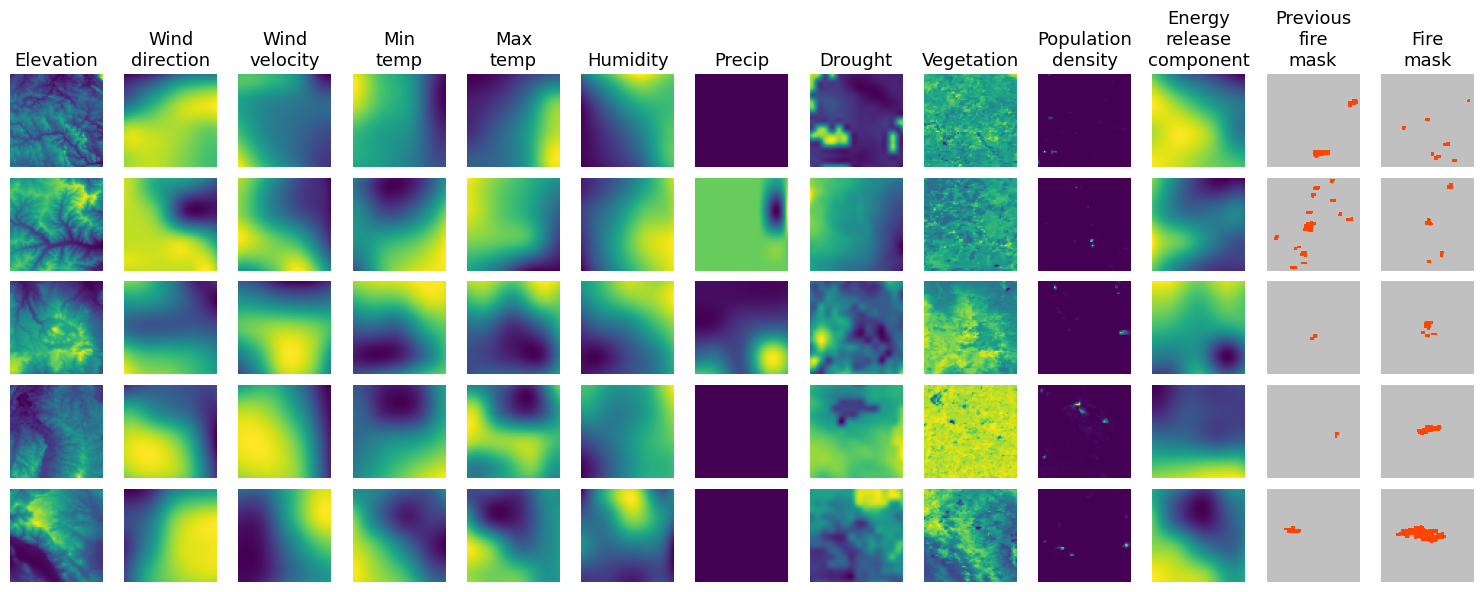

In [10]:
# Plot 5 training examples
plot_samples_from_dataset(train_dataset, 5)

In [41]:
for inputs, labels in train_dataset.take(1):
    print("Input shape:", inputs.shape)
    print("Label shape:", labels.shape)

Input shape: (16, 64, 64, 12)
Label shape: (16, 64, 64, 1)


# Evaluation metrics

To test how well the predicted fire mask is, we can test it against the TEST_FILES dataset. This is done using the Intersection Over Union (IOU, also known as the Jaccard Index). It essentially calculates to what extent your predicted image overlaps with the ground-truth image found in the dataset relative to the union of both images. The following function can be used:

In [11]:
def IoU_metric(real_mask: tf.Tensor, predicted_mask: tf.Tensor) -> float:
    """
    Calculation of intersection over union metric.

    Args:
        real_mask (Tensor): Ground-truth mask
        predicted_mask (Tensor): Mask predicted by model
    Returns:
        (float): IoU metric value
    """
    real_mask = tf.where(real_mask < 0, 0, real_mask)

    intersection = np.logical_and(real_mask, predicted_mask)
    union = np.logical_or(real_mask, predicted_mask)

    if np.sum(union) == 0:
        return 1
    return np.sum(intersection) / np.sum(union)

Evaluation loop: 

In [12]:
def evaluate_model(model, eval_dataset: tf.data.Dataset) -> float:
    """
    Evaluation of a model using the Intersection over Union (IoU) metric.

    Args:
        model: Trained model to evaluate.
        eval_dataset (tf.data.Dataset): Dataset containing evaluation inputs and ground-truth labels.

    Returns:
        (float): Mean IoU metric value across the evaluation dataset.
    """

    IoU_measures = []
    for inputs, labels in eval_dataset:
        # Get model predictions with prediction shape (N, W, H)
        predictions = model.predict(inputs)
        predictions = tf.where(predictions > 0.5, 1, 0)

        for i in range(inputs.shape[0]):
            IoU_measures.append(IoU_metric(labels[i, :, :, 0], predictions[i, :, :]))

    return np.mean(IoU_measures)

# Training 

Here, we have chosen 2 epochs to keep the training time to a reasonable amount. Change this however you find necessary taking into account that increasing the nuber of epochs also increases computation time. Also note that more epochs does not necessarily equate to better performance as it increases the risk of overfitting, leading to loss of generizability. Validation_dataset is used to track the progress of our model's accuracy and loss during training.

# Testing

To test our model, we now benchmark it against unseen data with the test_dataset part of the dataset.

In [29]:
# Test loss and IoU metric
print("Evaluate on test data")

IoU = evaluate_model(model, test_dataset)

print(f"IoU Score: {IoU:.4f}")

Evaluate on test data
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 314ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 24ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s

# Inference on test set 

In [30]:
def show_inference(
    n_rows: int,
    features: tf.Tensor,
    label: tf.Tensor,
    prediction_function: Callable[[tf.Tensor], tf.Tensor],
) -> None:
    """
    Show model inference through images.

    Args:
        n_rows (int): Number of rows for subplots.
        features (tf.Tensor): Input features.
        label (tf.Tensor): True labels.
        prediction_function (Callable[[tf.Tensor], tf.Tensor]): Function for model prediction.
    """

    # Variables for controllong the color map for the fire masks
    CMAP = colors.ListedColormap(["black", "silver", "orangered"])
    BOUNDS = [-1, -0.1, 0.001, 1]
    NORM = colors.BoundaryNorm(BOUNDS, CMAP.N)

    fig = plt.figure(figsize=(15, n_rows * 4))

    prediction = prediction_function(features)
    for i in range(n_rows):
        plt.subplot(n_rows, 3, i * 3 + 1)
        plt.title("Previous day fire")
        plt.imshow(features[i, :, :, -1], cmap=CMAP, norm=NORM)
        plt.axis("off")
        plt.subplot(n_rows, 3, i * 3 + 2)
        plt.title("True next day fire")
        plt.imshow(label[i, :, :, 0], cmap=CMAP, norm=NORM)
        plt.axis("off")
        plt.subplot(n_rows, 3, i * 3 + 3)
        plt.title("Predicted next day fire")
        plt.imshow(prediction[i, :, :])
        plt.axis("off")
    plt.tight_layout()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step


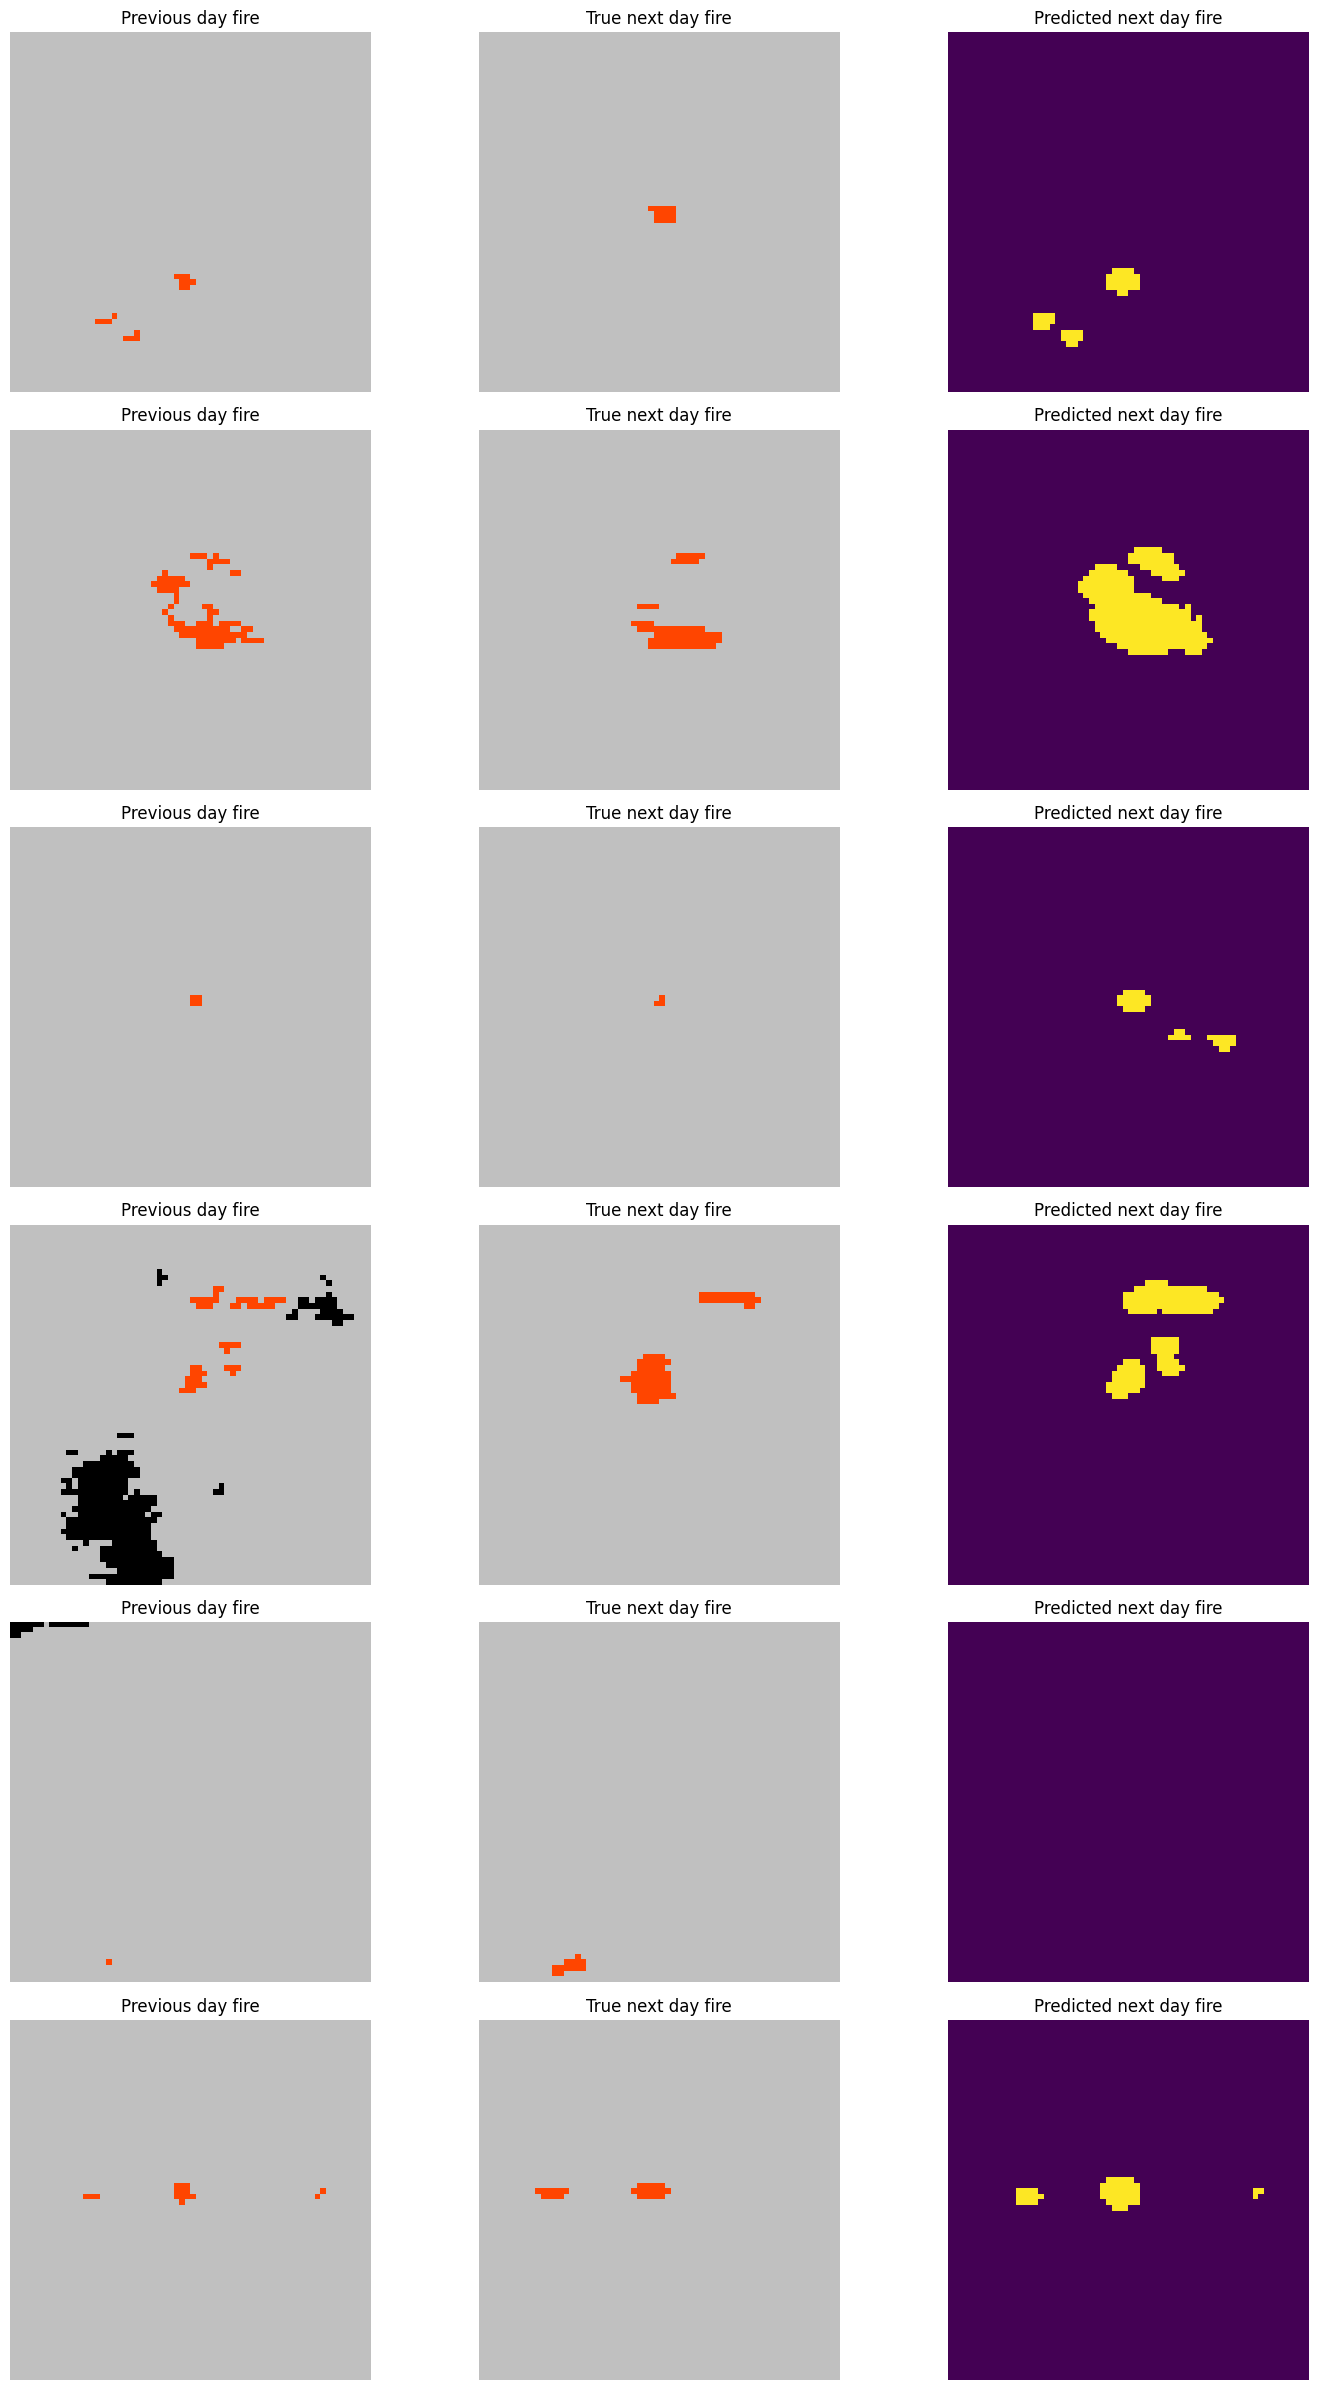

In [31]:
features, labels = next(iter(test_dataset))
show_inference(6, features, labels, lambda x: tf.where(model.predict(x) > 0.5, 1, 0)[:, :, :, 0])